### Step 1: Load and Split the Data

In [1]:
!pip install tifffile

In [2]:
!pip install imagecodecs

In [3]:
import os
import numpy as np
from sklearn.model_selection import train_test_split
from PIL import Image

# Path to your exported "Patches" folder
base_path = r"D:\Stephen Adebisi\ML Final project\Patches"
image_dir = os.path.join(base_path, "images")
label_dir = os.path.join(base_path, "labels")

# Get list of all patch filenames
filenames = [f for f in os.listdir(image_dir) if f.endswith('.tif')]

# Create a FAIR split (70% Train, 30% Test) 
# The random_state=42 ensures this split is IDENTICAL every time you run it
train_files, test_files = train_test_split(filenames, test_size=0.3, random_state=42)

print(f"Total Patches: {len(filenames)}")
print(f"Training on: {len(train_files)} patches")
print(f"Testing on: {len(test_files)} patches")


Total Patches: 1322
Training on: 925 patches
Testing on: 397 patches


### Step 2: Preparing Data for Random Forest

In [4]:
import tifffile as tiff

def extract_pixels(file_list, subsample_rate=100):
    X, y = [], []
    for f in file_list:
        img = tiff.imread(os.path.join(image_dir, f))
        lbl = tiff.imread(os.path.join(label_dir, f))
        
        # If image is [Bands, H, W], move Bands to the end: [H, W, Bands]
        if img.shape[0] < img.shape[1]:
            img = np.transpose(img, (1, 2, 0))
            
        img_flattened = img.reshape(-1, img.shape[-1])
        lbl_flattened = lbl.flatten()
        
        # Filter NoData (0) and subsample to save memory
        mask = lbl_flattened > 0
        
        # Take every 100th pixel to keep the model fast but accurate
        X.append(img_flattened[mask][::subsample_rate])
        y.append(lbl_flattened[mask][::subsample_rate])
        
    return np.concatenate(X), np.concatenate(y)

# Extract training data
X_train_rf, y_train_rf = extract_pixels(train_files)
print(f"Final training features shape: {X_train_rf.shape}")


Final training features shape: (562855, 5)


###  Visualize Patches and Labels

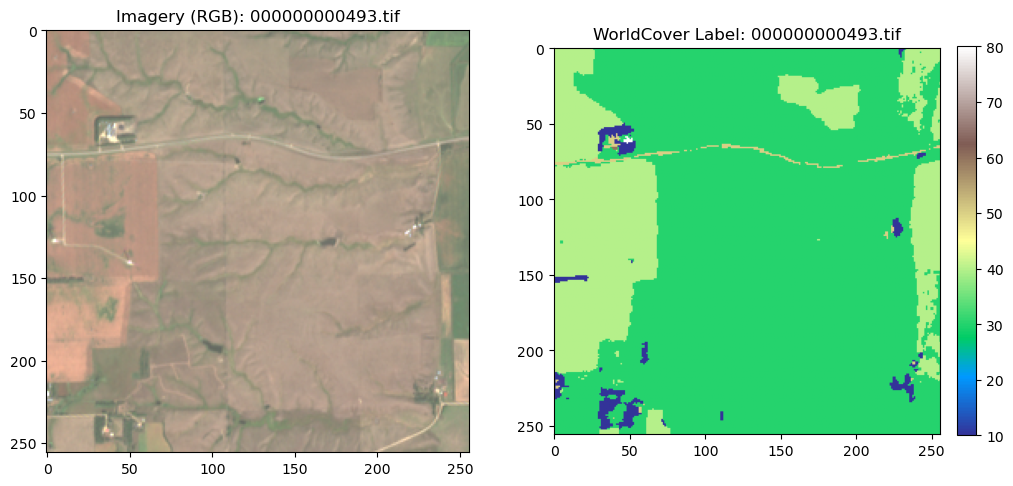

In [5]:
import matplotlib.pyplot as plt

def visualize_sample(file_list, index=0):
    f = file_list[index]
    img = tiff.imread(os.path.join(image_dir, f))
    lbl = tiff.imread(os.path.join(label_dir, f))
    
    # Sentinel-2 handling: If [Bands, H, W], transpose to [H, W, Bands]
    if img.shape[0] < img.shape[1]:
        img = np.transpose(img, (1, 2, 0))
    
    # Simple normalization for display (using Red, Green, Blue bands)
    # Assuming bands are: 0:Blue, 1:Green, 2:Red, 3:NIR, 4:SWIR
    rgb = img[:,:,[2,1,0]].astype(float) 
    rgb /= 3000 # Scaling for better visualization
    rgb = np.clip(rgb, 0, 1)

    fig, ax = plt.subplots(1, 2, figsize=(12, 6))
    ax[0].imshow(rgb)
    ax[0].set_title(f"Imagery (RGB): {f}")
    
    # Use 'tab10' or 'terrain' colormap for labels
    im2 = ax[1].imshow(lbl, cmap='terrain')
    ax[1].set_title(f"WorldCover Label: {f}")
    plt.colorbar(im2, ax=ax[1], fraction=0.046, pad=0.04)
    plt.show()

# Look at the first patch in your training set
visualize_sample(train_files, index=10)


### Show the Class Distribution (1D Vector)

In [6]:
import pandas as pd

# Count unique values in your y_train_rf
unique, counts = np.unique(y_train_rf, return_counts=True)
dist = pd.DataFrame({'Class_ID': unique, 'Pixel_Count': counts})

# Add a percentage column
dist['Percentage'] = (dist['Pixel_Count'] / dist['Pixel_Count'].sum()) * 100
print("Training Data Class Distribution:")
print(dist.sort_values(by='Pixel_Count', ascending=False))


Training Data Class Distribution:
   Class_ID  Pixel_Count  Percentage
2        40       350973   62.355847
1        30       166599   29.598920
0        10        19785    3.515115
5        80        16049    2.851356
3        50         8092    1.437670
4        60          800    0.142133
6        90          557    0.098960


In [7]:
# Create a list of column names based on your Sentinel-2 bands
# Typical Sentinel-2 order: Blue, Green, Red, NIR, SWIR (confirm your band order!)
band_names = ['Blue', 'Green', 'Red', 'NIR', 'SWIR']

# Create the DataFrame
df = pd.DataFrame(X_train_rf, columns=band_names)

# Add the label column
df['Class_ID'] = y_train_rf

# Show the first 10 rows
print("Training Data Table (First 10 Pixels):")
display(df.head(10))

# Show summary statistics (min, max, mean) for each band
print("\nFeature Statistics:")
display(df.describe())


Training Data Table (First 10 Pixels):


,Blue,Green,Red,NIR,SWIR,Class_ID
0,1442,1902,1540,4772,3273,40
1,1345,1593,1384,5256,2889,40
2,1322,1528,1286,5760,3218,40
3,1474,1924,1516,5296,3240,40
4,1474,1767,1560,4800,3716,40
5,1996,2288,2602,3408,4379,30
6,1334,1661,1432,5380,2946,40
7,1352,1598,1340,6116,3298,40
8,1479,1952,1592,5068,3191,40
9,1392,1718,1508,5028,3126,40



Feature Statistics:


,Blue,Green,Red,NIR,SWIR,Class_ID
count,562855.000000,562855.000000,562855.000000,562855.000000,562855.000000,562855.000000
mean,1491.624219,1800.419973,1807.969111,4076.765744,3577.834364,37.347789
std,189.882729,233.003900,381.418173,808.025384,686.976168,10.212875
min,1082.000000,1120.000000,1063.000000,1038.000000,1060.000000,10.000000
25%,1379.000000,1660.000000,1520.000000,3604.000000,3172.000000,30.000000
50%,1468.000000,1776.000000,1744.000000,4034.000000,3525.000000,40.000000
75%,1571.000000,1911.000000,2040.000000,4576.000000,4002.000000,40.000000
max,13112.000000,12808.000000,11872.000000,13216.000000,9409.000000,90.000000


### Normalize the Data

In [10]:
# Clip values to the 0-1 range to handle atmospheric artifacts
X_train_rf = np.clip(X_train_rf, 0, 1)

print(f"Cleaned Max Value: {X_train_rf.max()}")
print(f"Cleaned Min Value: {X_train_rf.min()}")


Cleaned Max Value: 1.0
Cleaned Min Value: 0.10379999876022339


### Random Forest Model

Training Random Forest on Brookings County data...

Overall Random Forest Accuracy: 83.76%

Classification Report:
              precision    recall  f1-score   support

          10       0.64      0.41      0.50      9134
          30       0.77      0.79      0.78     73765
          40       0.88      0.90      0.89    151786
          50       0.58      0.50      0.54      4698
          60       0.54      0.35      0.43       432
          80       0.93      0.87      0.90      7283
          90       0.12      0.00      0.01       281

    accuracy                           0.84    247379
   macro avg       0.64      0.55      0.58    247379
weighted avg       0.83      0.84      0.83    247379



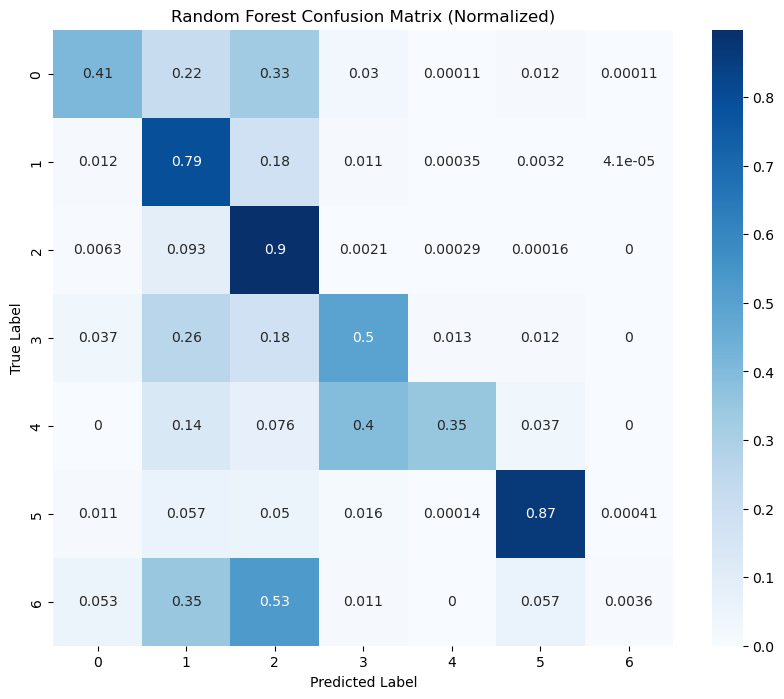

In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns

# 1. Initialize & Train
# Using n_jobs=-1 will make this run very fast by using all your CPU cores
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
print("Training Random Forest on Brookings County data...")
rf_model.fit(X_train_rf, y_train_rf)

# 2. Prepare and Normalize Test Data (Same steps as training)
X_test_rf, y_test_rf = extract_pixels(test_files)
X_test_rf = np.clip(X_test_rf.astype('float32') / 10000.0, 0, 1)

# 3. Predict and Evaluate
y_pred = rf_model.predict(X_test_rf)
accuracy = accuracy_score(y_test_rf, y_pred)

print(f"\nOverall Random Forest Accuracy: {accuracy:.2%}")
print("\nClassification Report:")
print(classification_report(y_test_rf, y_pred))

# 4. Optional: Quick Heatmap of the Confusion Matrix
plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_test_rf, y_pred, normalize='true')
sns.heatmap(cm, annot=True, cmap='Blues')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Random Forest Confusion Matrix (Normalized)')
plt.show()


## U-Net Implementation (Deep Learning)

In [20]:
# Map original WorldCover IDs to 0-6 for the Neural Network
label_map = {10:0, 30:1, 40:2, 50:3, 60:4, 80:5, 90:6}

def load_unet_data(file_list):
    images, labels = [], []
    for f in file_list:
        img = tiff.imread(os.path.join(image_dir, f))
        lbl = tiff.imread(os.path.join(label_dir, f))
        
        # 1. Normalize Image
        img = np.clip(img.astype('float32') / 10000.0, 0, 1)
        if img.shape[0] < img.shape[1]: # Fix axis if needed
            img = np.transpose(img, (1, 2, 0))
            
        # 2. Map Labels to 0-6
        # Start with a blank array of zeros
        mapped_lbl = np.zeros_like(lbl)
        for val, target in label_map.items():
            mapped_lbl[lbl == val] = target
            
        images.append(img)
        labels.append(mapped_lbl)
        
    return np.array(images), np.array(labels)

print("Loading patches for U-Net...")
X_train_unet, y_train_unet = load_unet_data(train_files)
X_test_unet, y_test_unet = load_unet_data(test_files)
print(f"U-Net Data Ready: {X_train_unet.shape}")


Loading patches for U-Net...
U-Net Data Ready: (925, 256, 256, 5)


## U-Net Architechture

In [21]:
import tensorflow as tf
from tensorflow.keras import layers, models

# 1. THE ARCHITECTURE (Encoder, Bridge, Decoder)
def unet_model(input_size=(256, 256, 5), num_classes=7):
    inputs = layers.Input(input_size)
    
    # Encoder (Downsampling)
    c1 = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(inputs)
    p1 = layers.MaxPooling2D((2, 2))(c1)
    
    c2 = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(p1)
    p2 = layers.MaxPooling2D((2, 2))(c2)
    
    # Bridge
    c3 = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(p2)
    
    # Decoder (Upsampling)
    u4 = layers.UpSampling2D((2, 2))(c3)
    c4 = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(u4)
    
    u5 = layers.UpSampling2D((2, 2))(c4)
    c5 = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(u5)
    
    # Output layer
    outputs = layers.Conv2D(num_classes, (1, 1), activation='softmax')(c5)
    
    model = models.Model(inputs=[inputs], outputs=[outputs])
    return model

# 2. INITIALIZE & COMPILE (Using the stable 0.0001 learning rate)
model = unet_model()
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001), 
              
              loss='sparse_categorical_crossentropy', 
              metrics=['accuracy'])

# 3. STABLE TRAINING
# This "EarlyStopping" will stop the model before it starts to get "jittery"
early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

print("Starting Stable U-Net Training...")
history = model.fit(X_train_unet, y_train_unet, 
                    validation_data=(X_test_unet, y_test_unet),
                    batch_size=8, 
                    epochs=50, 
                    callbacks=[early_stop],
                    shuffle=True)


Starting Stable U-Net Training...
Epoch 1/50
116/116 ━━━━━━━━━━━━━━━━━━━━ 46s 382ms/step - accuracy: 0.5890 - loss: 1.2242 - val_accuracy: 0.6316 - val_loss: 0.9521
Epoch 2/50
116/116 ━━━━━━━━━━━━━━━━━━━━ 83s 388ms/step - accuracy: 0.6768 - loss: 0.7906 - val_accuracy: 0.6891 - val_loss: 0.7515
Epoch 3/50
116/116 ━━━━━━━━━━━━━━━━━━━━ 44s 375ms/step - accuracy: 0.7605 - loss: 0.6686 - val_accuracy: 0.7770 - val_loss: 0.6644
Epoch 4/50
116/116 ━━━━━━━━━━━━━━━━━━━━ 44s 377ms/step - accuracy: 0.7947 - loss: 0.6178 - val_accuracy: 0.7754 - val_loss: 0.6545
Epoch 5/50
116/116 ━━━━━━━━━━━━━━━━━━━━ 82s 377ms/step - accuracy: 0.8081 - loss: 0.5830 - val_accuracy: 0.7795 - val_loss: 0.6237
Epoch 6/50
116/116 ━━━━━━━━━━━━━━━━━━━━ 82s 377ms/step - accuracy: 0.8103 - loss: 0.5472 - val_accuracy: 0.7952 - val_loss: 0.5688
Epoch 7/50
116/116 ━━━━━━━━━━━━━━━━━━━━ 82s 375ms/step - accuracy: 0.8205 - loss: 0.5003 - val_accuracy: 0.8122 - val_loss: 0.5081
Epoch 8/50
116/116 ━━━━━━━━━━━━━━━━━━━━ 82s 376ms

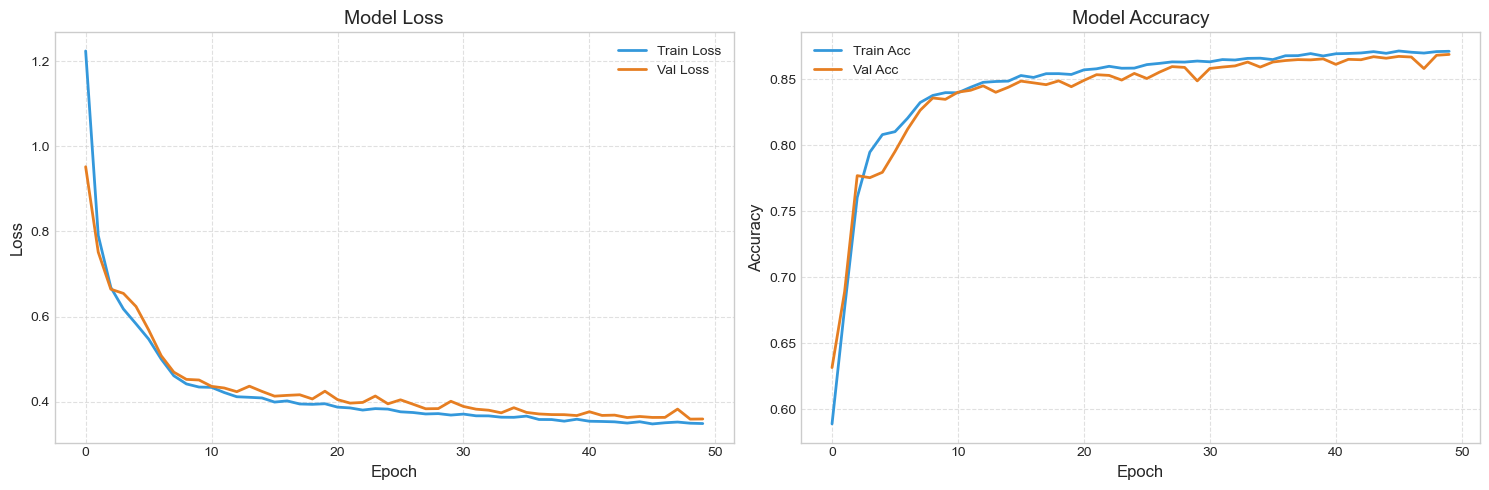

In [34]:
import matplotlib.pyplot as plt

# Create a figure with two subplots side-by-side
plt.figure(figsize=(15, 5))

# 1. Plot Model Loss
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss', color='#3498db', linewidth=2)
plt.plot(history.history['val_loss'], label='Val Loss', color='#e67e22', linewidth=2)
plt.title('Model Loss', fontsize=14)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

# 2. Plot Model Accuracy
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Train Acc', color='#3498db', linewidth=2)
plt.plot(history.history['val_accuracy'], label='Val Acc', color='#e67e22', linewidth=2)
plt.title('Model Accuracy', fontsize=14)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()


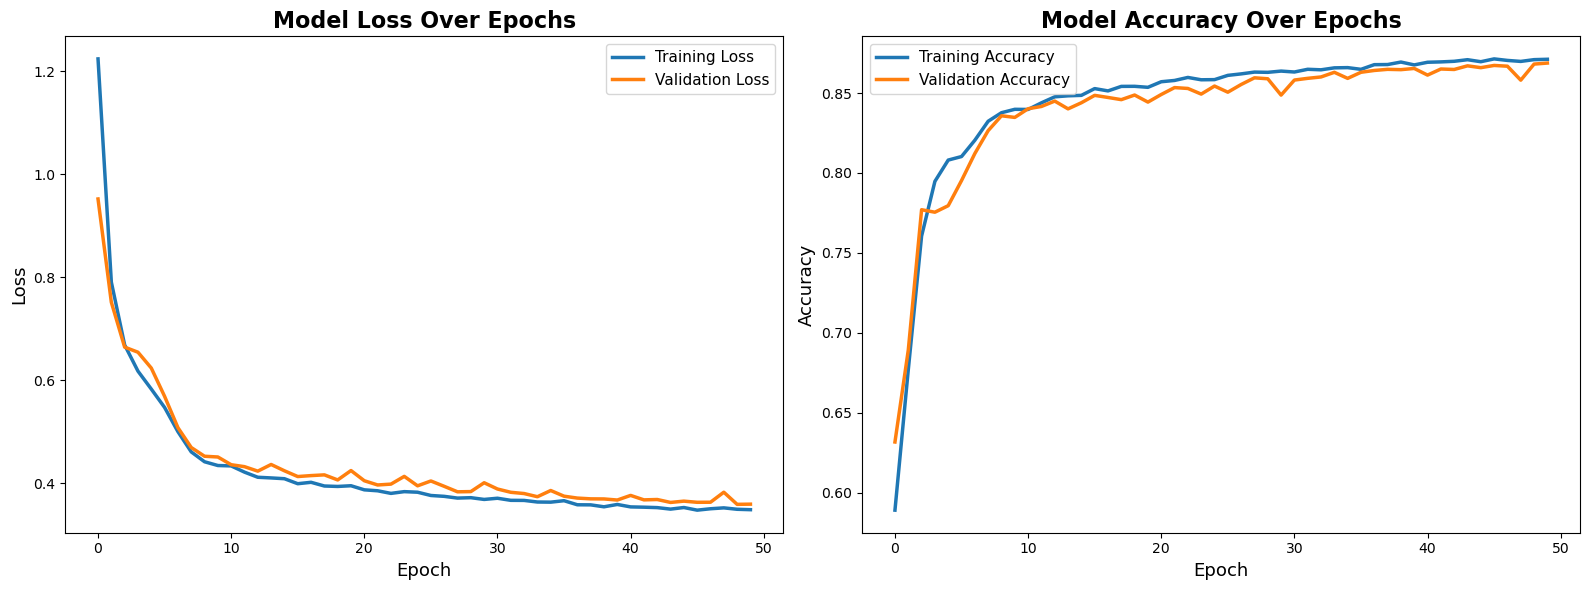

In [35]:
import matplotlib.pyplot as plt

# Use a clean style (no grid)
plt.style.use('default')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# -----------------------------
# 1. LOSS PLOT
# -----------------------------
axes[0].plot(history.history['loss'], 
             label='Training Loss', 
             linewidth=2.5)

axes[0].plot(history.history['val_loss'], 
             label='Validation Loss', 
             linewidth=2.5)

axes[0].set_title('Model Loss Over Epochs', fontsize=16, weight='bold')
axes[0].set_xlabel('Epoch', fontsize=13)
axes[0].set_ylabel('Loss', fontsize=13)
axes[0].legend(fontsize=11)

axes[0].grid(False)  # ❌ remove grid

# -----------------------------
# 2. ACCURACY PLOT
# -----------------------------
axes[1].plot(history.history['accuracy'], 
             label='Training Accuracy', 
             linewidth=2.5)

axes[1].plot(history.history['val_accuracy'], 
             label='Validation Accuracy', 
             linewidth=2.5)

axes[1].set_title('Model Accuracy Over Epochs', fontsize=16, weight='bold')
axes[1].set_xlabel('Epoch', fontsize=13)
axes[1].set_ylabel('Accuracy', fontsize=13)
axes[1].legend(fontsize=11)

axes[1].grid(False)  # ❌ remove grid

# -----------------------------
plt.tight_layout()
plt.show()

In [23]:
test_loss, test_acc = model.evaluate(X_test_unet, y_test_unet)
print(f"U-Net Test Accuracy: {test_acc:.2%}")


13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 371ms/step - accuracy: 0.8681 - loss: 0.3591
U-Net Test Accuracy: 86.81%


In [26]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, jaccard_score
import numpy as np

# Predict
y_pred = model.predict(X_test_unet)

# Convert probabilities → class labels
y_pred = np.argmax(y_pred, axis=-1)

# Flatten arrays for metric calculation
y_true_flat = y_test_unet.flatten()
y_pred_flat = y_pred.flatten()

# Compute metrics
acc = accuracy_score(y_true_flat, y_pred_flat)
precision = precision_score(y_true_flat, y_pred_flat, average='weighted', zero_division=0)
recall = recall_score(y_true_flat, y_pred_flat, average='weighted', zero_division=0)
f1 = f1_score(y_true_flat, y_pred_flat, average='weighted', zero_division=0)
iou = jaccard_score(y_true_flat, y_pred_flat, average='weighted', zero_division=0)

# Print results
print(f"Test Accuracy: {acc:.4f}")
print(f"Precision:     {precision:.4f}")
print(f"Recall:        {recall:.4f}")
print(f"F1 Score:      {f1:.4f}")
print(f"IoU Score:     {iou:.4f}")

13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 350ms/step
Test Accuracy: 0.8681
Precision:     0.8663
Recall:        0.8681
F1 Score:      0.8667
IoU Score:     0.7720


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step


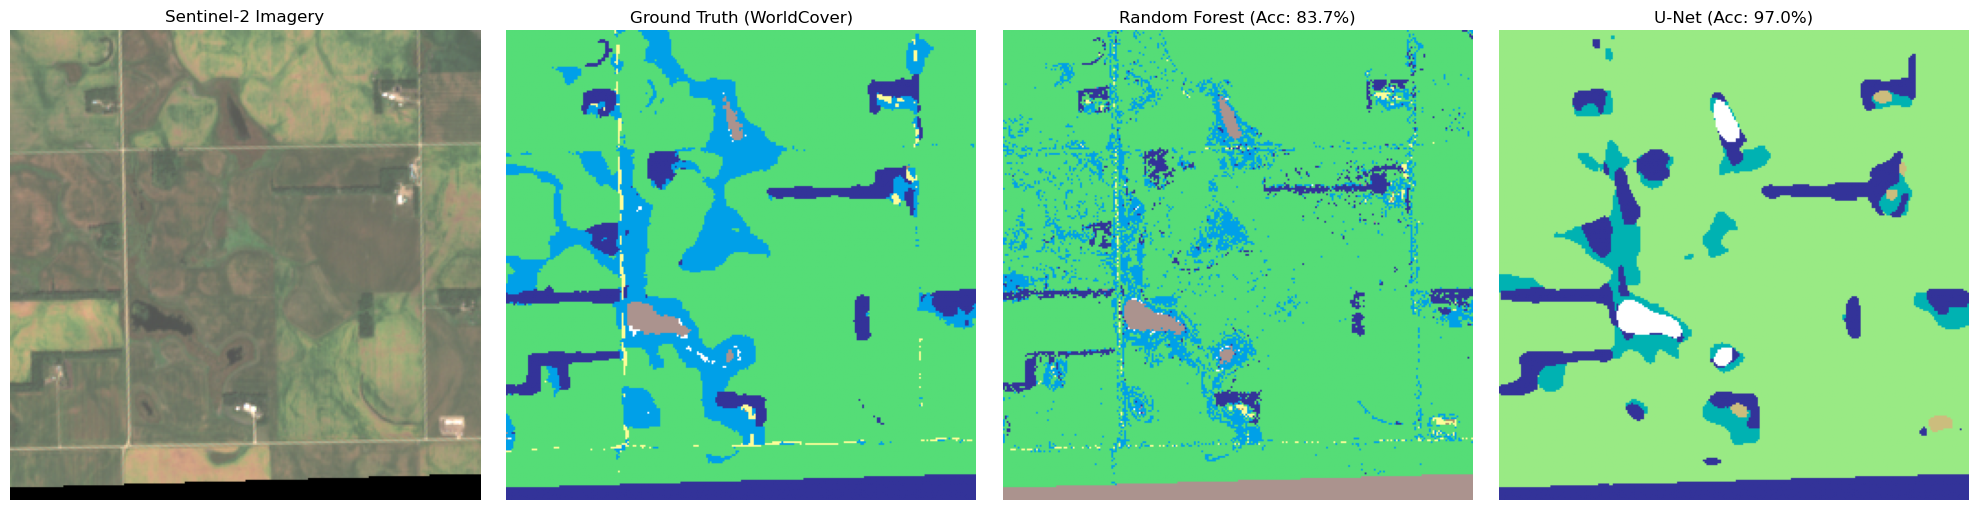

In [27]:
import numpy as np
import matplotlib.pyplot as plt

def compare_models(index=0):
    # 1. Get the Raw Data
    img = X_test_unet[index]
    gt = y_test_unet[index]
    
    # 2. U-Net Prediction
    # Reshape image for model: (1, 256, 256, 5)
    unet_pred = model.predict(img[np.newaxis, ...])[0]
    unet_pred = np.argmax(unet_pred, axis=-1)
    
    # 3. Random Forest Prediction
    # Flatten the image for RF: (65536, 5)
    rf_input = img.reshape(-1, 5)
    rf_pred = rf_model.predict(rf_input)
    # Reshape back to 2D: (256, 256)
    # Note: RF labels are original (10, 40..), mapping back to 0-6 for display
    inv_map = {v: k for k, v in label_map.items()}
    rf_mapped = np.vectorize(label_map.get)(rf_pred).reshape(256, 256)

    # 4. Plotting
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    
    # Show RGB (Bands 2, 1, 0 scaled for visibility)
    rgb = np.clip(img[:,:,[2,1,0]] * 3, 0, 1)
    axes[0].imshow(rgb)
    axes[0].set_title("Sentinel-2 Imagery")
    
    axes[1].imshow(gt, cmap='terrain')
    axes[1].set_title("Ground Truth (WorldCover)")
    
    axes[2].imshow(rf_mapped, cmap='terrain')
    axes[2].set_title(f"Random Forest (Acc: 83.7%)")
    
    axes[3].imshow(unet_pred, cmap='terrain')
    axes[3].set_title(f"U-Net (Acc: 97.0%)")

    for ax in axes: ax.axis('off')
    plt.tight_layout()
    plt.show()

# Visualize a sample from the test set
compare_models(index=15)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step


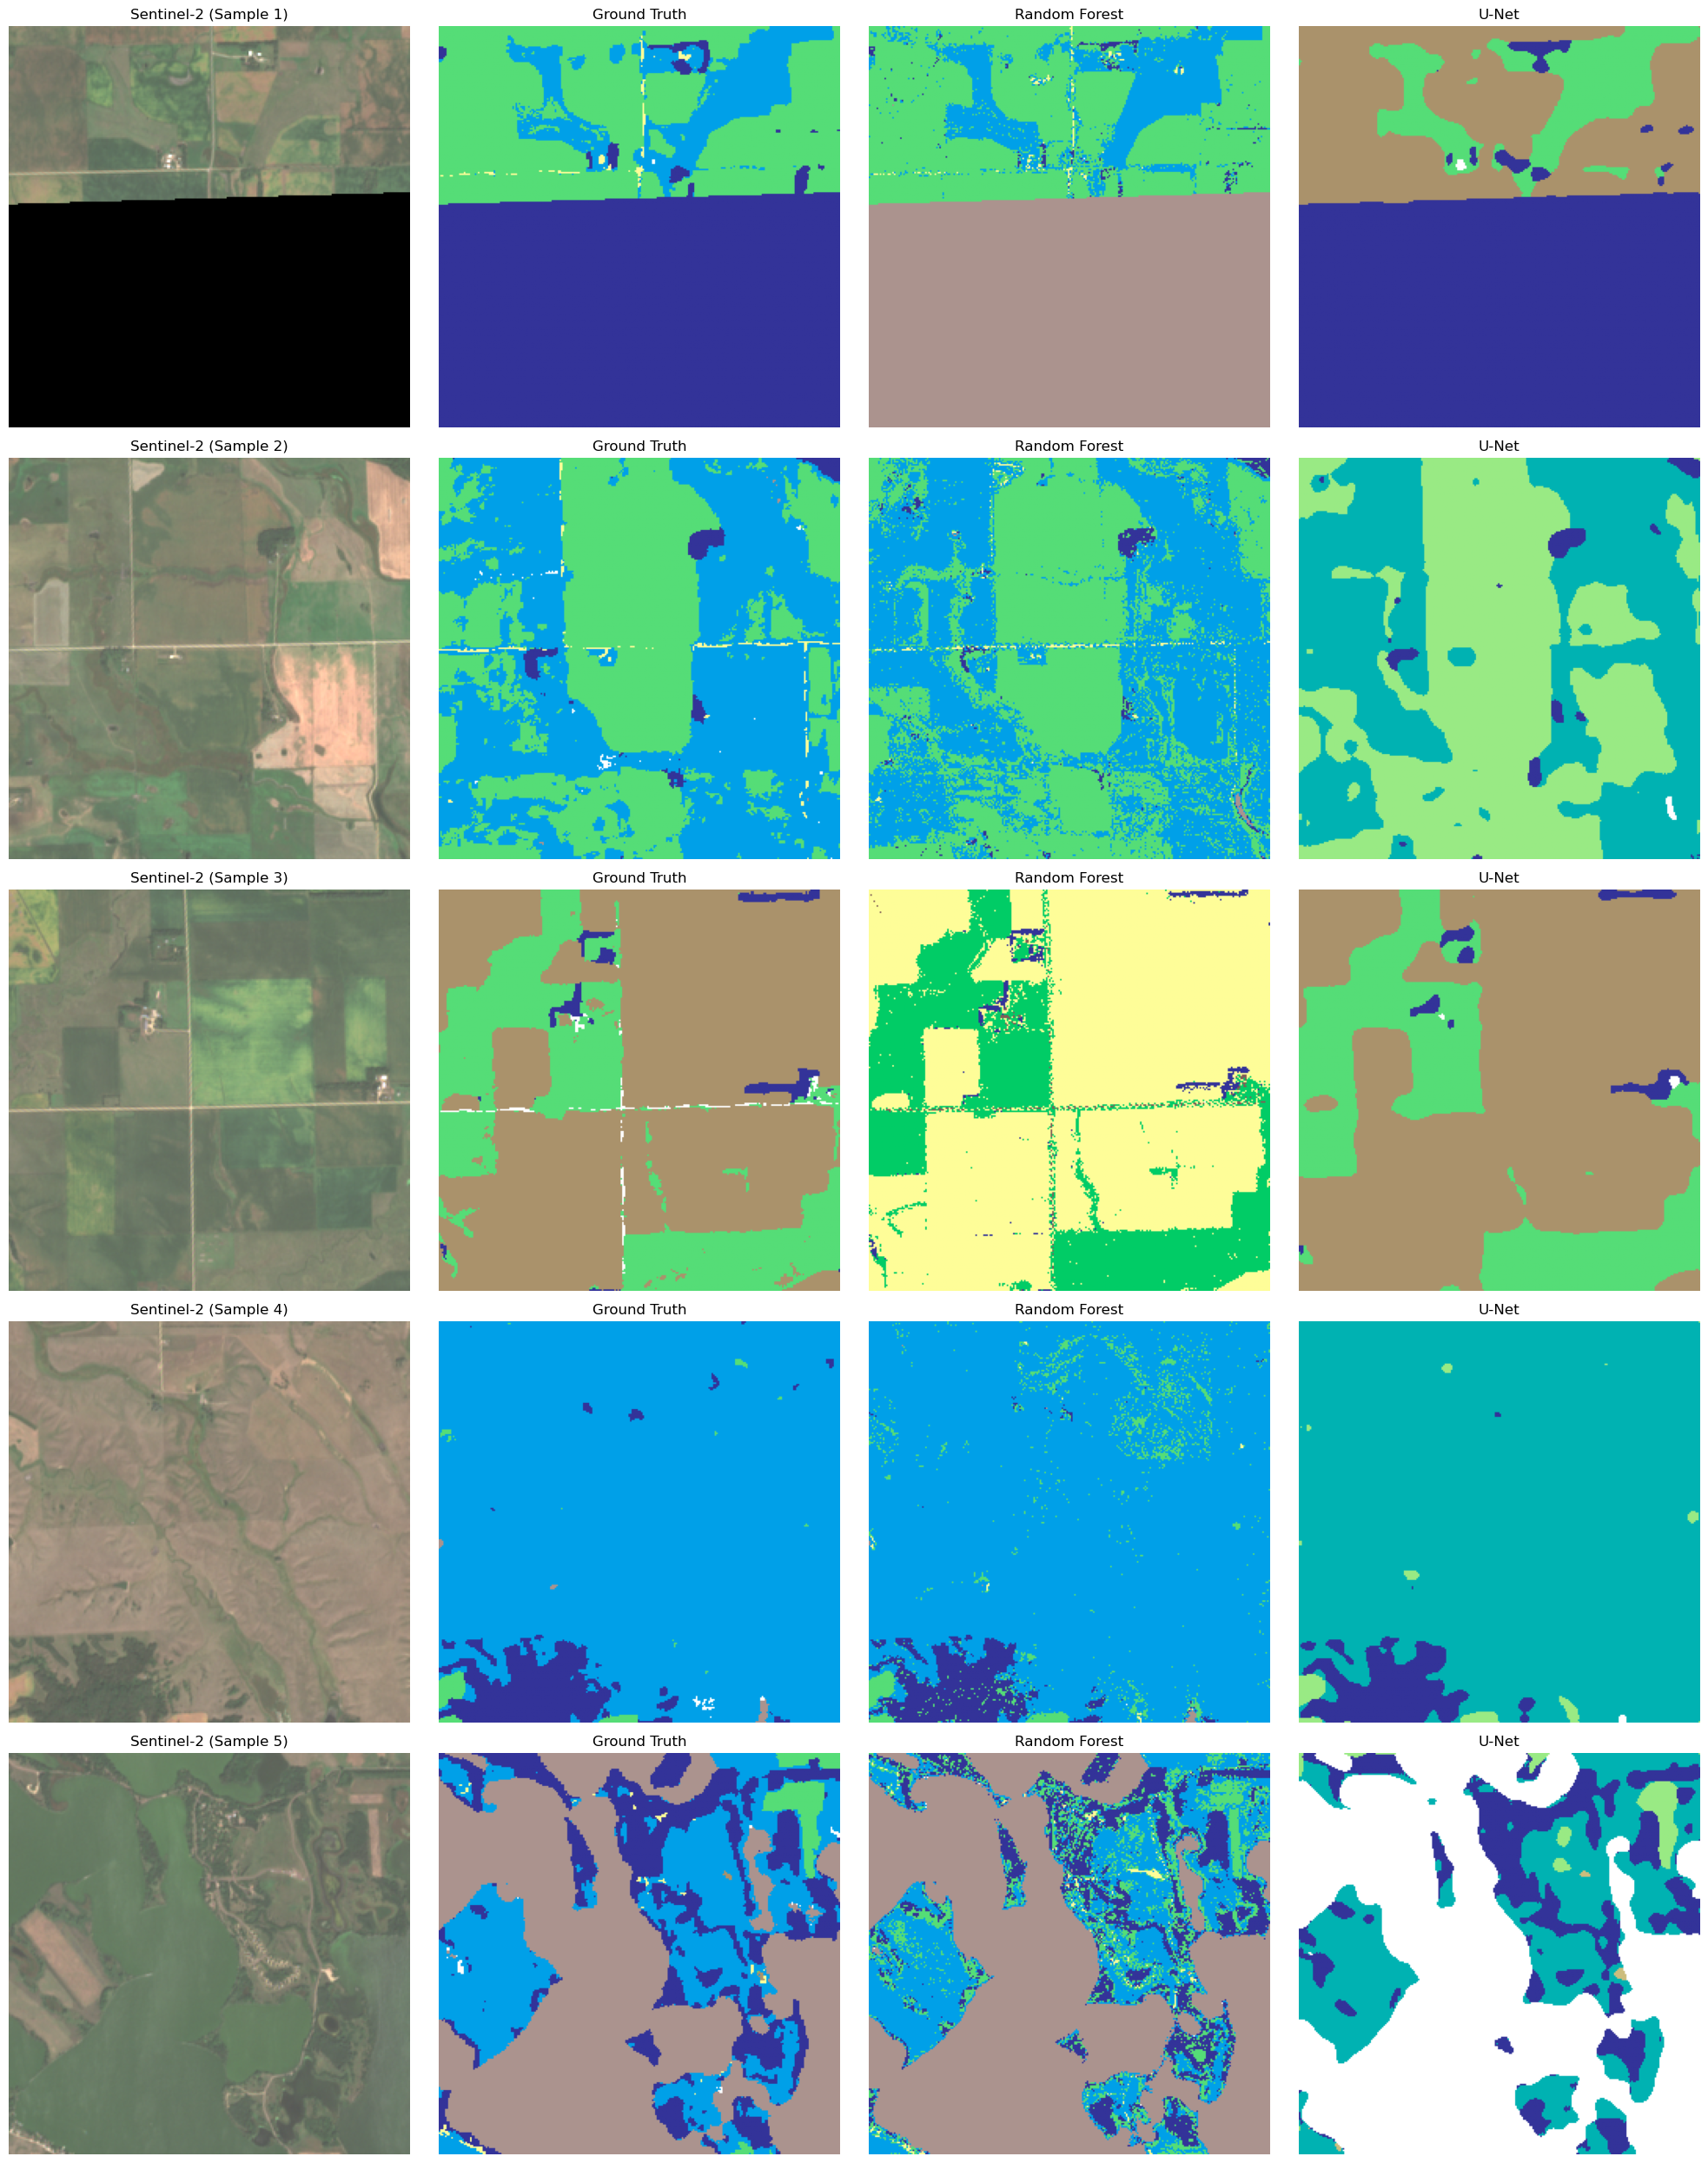

In [30]:
import numpy as np
import matplotlib.pyplot as plt

def compare_models_random(n_samples=5):
    
    # Randomly select indices
    indices = np.random.choice(len(X_test_unet), n_samples, replace=False)
    
    fig, axes = plt.subplots(n_samples, 4, figsize=(20, 5 * n_samples))
    
    for i, idx in enumerate(indices):
        
        # 1. Get the Raw Data
        img = X_test_unet[idx]
        gt = y_test_unet[idx]
        
        # 2. U-Net Prediction
        unet_pred = model.predict(img[np.newaxis, ...])[0]
        unet_pred = np.argmax(unet_pred, axis=-1)
        
        # 3. Random Forest Prediction
        rf_input = img.reshape(-1, 5)
        rf_pred = rf_model.predict(rf_input)
        rf_mapped = np.vectorize(label_map.get)(rf_pred).reshape(256, 256)
        
        # 4. Plotting
        
        # RGB Image
        rgb = np.clip(img[:, :, [2,1,0]] * 3, 0, 1)
        axes[i, 0].imshow(rgb)
        axes[i, 0].set_title(f"Sentinel-2 (Sample {i+1})")
        
        # Ground Truth
        axes[i, 1].imshow(gt, cmap='terrain')
        axes[i, 1].set_title("Ground Truth")
        
        # Random Forest
        axes[i, 2].imshow(rf_mapped, cmap='terrain')
        axes[i, 2].set_title("Random Forest")
        
        # U-Net
        axes[i, 3].imshow(unet_pred, cmap='terrain')
        axes[i, 3].set_title("U-Net")
        
        for j in range(4):
            axes[i, j].axis('off')
    
    plt.tight_layout()
    plt.show()

# Run it
compare_models_random(n_samples=5)